# 01 — Validación de BPSO y CBPSO-MIWS

Notebook de la **fase 1**: verifica que los datos, la función de fitness y los dos
algoritmos de PSO binario funcionan antes de correr los experimentos completos (fase 2).

1. Bases de datos cargadas y preprocesadas
2. Una corrida de BPSO y de CBPSO-MIWS en Ionosphere
3. Curvas de convergencia promedio (pocas corridas)
4. Esquemas de inercia que sorteó cada especie
5. Hallazgo: la columna ID de Glass filtra la etiqueta

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bfs.data import DATASETS, load_dataset, holdout_split
from bfs.fitness import FeatureSelectionProblem
from bfs.algorithms import ALGORITHMS

N, T = 10, 100   # Tabla 2 del artículo

## 1. Bases de datos

In [2]:
resumen = []
for name, (num, _) in DATASETS.items():
    ds = load_dataset(name)
    resumen.append({"#": num, "base": name, "instancias": ds.n_instances,
                    "variables": ds.n_features, "clases": ds.n_classes})
pd.DataFrame(resumen).set_index("#")

,base,instancias,variables,clases
#,,,,
1,breast_cancer_wisconsin,699,9,2
3,glass,214,9,6
3,glass_id,214,10,6
4,ionosphere,351,34,2
5,libras,360,90,15
7,breast_cancer_coimbra,116,9,2
8,lung_cancer,32,56,3


## 2. Una corrida en Ionosphere

Misma partición 80/20 (`seed=0`) para ambos algoritmos; cada uno con su propio generador aleatorio.

In [3]:
ds = load_dataset("ionosphere")
split = holdout_split(ds, seed=0)

resultados = {}
for alg in ["bpso", "cbpso_miws"]:
    problem = FeatureSelectionProblem(split)
    res = ALGORITHMS[alg](problem, ds.n_features, N, T, np.random.default_rng(0))
    resultados[alg] = res
    print(f"{alg:11s} fitness={res.best_fitness:.4f}  accuracy={problem.accuracy(res.mask):.2f}%  "
          f"variables={res.n_selected}/{ds.n_features}  tiempo={res.elapsed:.2f}s")
    print("            seleccionadas:", res.selected.tolist())

bpso        fitness=0.0851  accuracy=91.55%  variables=5/34  tiempo=1.03s
            seleccionadas: [5, 6, 7, 16, 24]
cbpso_miws  fitness=0.1142  accuracy=88.73%  variables=9/34  tiempo=1.24s
            seleccionadas: [0, 2, 7, 16, 18, 20, 26, 27, 29]


## 3. Curvas de convergencia promedio

El artículo promedia 20 corridas; aquí usamos 5 para que sea rápido. La corrida *r*
usa la partición `seed=r` y el generador `1000 + r` en ambos algoritmos.

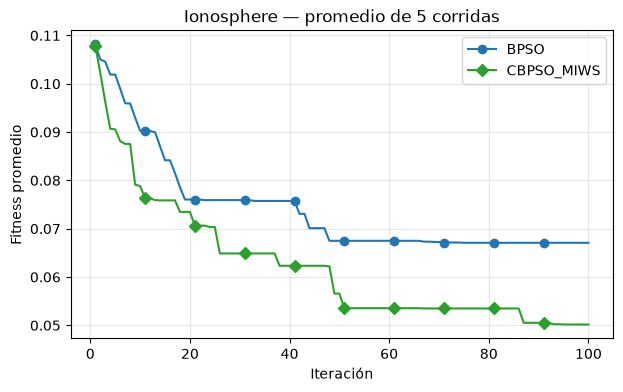

In [4]:
RUNS = 5
curvas = {alg: [] for alg in ["bpso", "cbpso_miws"]}
for r in range(RUNS):
    split = holdout_split(ds, seed=r)
    for alg in curvas:
        problem = FeatureSelectionProblem(split)
        res = ALGORITHMS[alg](problem, ds.n_features, N, T, np.random.default_rng(1000 + r))
        curvas[alg].append(res.curve)

fig, ax = plt.subplots(figsize=(7, 4))
estilos = {"bpso": dict(marker="o", color="tab:blue"),
           "cbpso_miws": dict(marker="D", color="tab:green")}
for alg, cs in curvas.items():
    ax.plot(np.arange(1, T + 1), np.mean(cs, axis=0), label=alg.upper(),
            markevery=10, **estilos[alg])
ax.set(xlabel="Iteración", ylabel="Fitness promedio",
       title=f"Ionosphere — promedio de {RUNS} corridas")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 4. Multiple Inertia Weight Strategy en acción

Cada especie sortea un esquema (1–4) en cada iteración (ec. 10). Abajo, el esquema elegido
por especie y el valor de *w* resultante.

Tamaño de cada especie: [4, 3, 3]
Veces que se sorteó cada esquema: {1: 82, 2: 57, 3: 85, 4: 76}


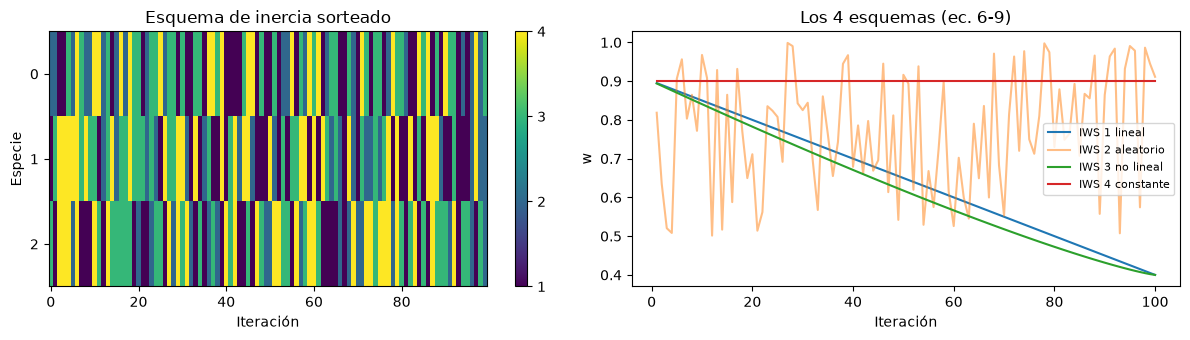

In [5]:
from bfs.algorithms.cbpso_miws import inertia_weight

hist = resultados["cbpso_miws"].extra["iws_history"]   # (T, ns)
print("Tamaño de cada especie:", resultados["cbpso_miws"].extra["species_sizes"])
esquemas, cuentas = np.unique(hist, return_counts=True)
print("Veces que se sorteó cada esquema:", {int(e): int(c) for e, c in zip(esquemas, cuentas)})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
im = axes[0].imshow(hist.T, aspect="auto", cmap="viridis", interpolation="nearest")
axes[0].set(xlabel="Iteración", ylabel="Especie", yticks=range(hist.shape[1]),
            title="Esquema de inercia sorteado")
fig.colorbar(im, ax=axes[0], ticks=[1, 2, 3, 4])

t = np.arange(1, T + 1)
rng = np.random.default_rng(0)
kw = dict(wmax=0.9, wmin=0.4, w0=0.9, p=1.2)
for s, nombre in zip([1, 2, 3, 4], ["IWS 1 lineal", "IWS 2 aleatorio", "IWS 3 no lineal", "IWS 4 constante"]):
    axes[1].plot(t, [inertia_weight(s, ti, T, rng, **kw) for ti in t], label=nombre,
                 alpha=0.5 if s == 2 else 1)
axes[1].set(xlabel="Iteración", ylabel="w", title="Los 4 esquemas (ec. 6-9)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Hallazgo: la columna ID de Glass

La Tabla 1 del artículo reporta Glass con **10** variables, pero el archivo de UCI tiene
9 variables químicas + un **ID** consecutivo. Como las filas vienen ordenadas por clase,
el ID prácticamente revela la etiqueta. Comparamos ambas versiones:

In [6]:
filas = []
for name in ["glass", "glass_id"]:
    d = load_dataset(name)
    for r in range(RUNS):
        problem = FeatureSelectionProblem(holdout_split(d, seed=r))
        res = ALGORITHMS["cbpso_miws"](problem, d.n_features, N, T, np.random.default_rng(1000 + r))
        filas.append({"base": name, "accuracy": problem.accuracy(res.mask),
                      "variables": res.n_selected,
                      "usa_ID": bool(name == "glass_id" and res.mask[0])})
glass = pd.DataFrame(filas)
glass.groupby("base")[["accuracy", "variables", "usa_ID"]].mean().round(2)

,accuracy,variables,usa_ID
base,,,
glass,81.40,3.6,0.0
glass_id,99.07,2.4,1.0


Con el ID, la exactitud se acerca al **98.37 %** que reporta el artículo para CBPSO-MIWS;
sin él cae cerca de 80 %. Esto sugiere que el artículo incluyó el ID como variable, y se
discutirá en el reporte. En los experimentos de la fase 2 se reportan ambas versiones.